# Assignment 2: Logistic Regression 

**Overview:**

In this assignment, you will conduct two additional analyses of the Columbia Speed Dating Experiment using logistic regression.
1. Test whether the associations between profile features (e.g., demographic variables and trait ratings) and sending a like differ by gender.
2. Test whether an overconfidence proxy is associated with receiving a like.

**Instructions:**

1. Put all written answers in the markdown cells below the question statement.
2. Keep code output.
3. Each group submits 1 notebook. 
 

## Set up dataset

Cell output is not required
<h4 style="color:blue">Complete the code cells below:</h4> 

In [1]:
#======== Load Package: 
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)


from ISLP import confusion_table

In [2]:
# Load the dataset
dating = pd.read_csv("SpeedDatingData.csv", encoding="ISO-8859-1")

# Exclude waves 6, 7, 8, and 9
dating = dating.loc[~dating["wave"].isin([6, 7, 8, 9])].copy()


In [3]:
#====== Extract Relavant Vars:
pre_cols = [
    "iid", "gender", "age",  
    # self-eval (pre-survey)
    "attr3_1", "intel3_1", "sinc3_1", "fun3_1", 
     # partner-eval (date)
    "attr_o", "sinc_o", "intel_o","fun_o", 
    #eval of partner
    "attr","sinc","intel","fun",
    # match data (dating outcome)
      "dec","dec_o" ]

dating_sample=dating[pre_cols]

### Task 0: General Information of the Data

1. Report the total # of rows with missing values (cell output)
2. For each variable, compute the  total # of missing values and the percentage of missing values in the same table (cell output)

<h4 style="color:blue">Please complete the code cells below:</h4> 

In [4]:
# Count rows with at least one missing value
missing_total = dating_sample.isna().any(axis=1).sum()

# Count all rows
total_record = len(dating_sample)

print('Out of', total_record, 'records,', missing_total,
      'contain at least one missing value.')

Out of 6816 records, 751 contain at least one missing value.


In [5]:
#----- closer look at missing

# Count missing values for each variable
missing_counts = dating_sample.isna().sum()

# Calculate the percentage of missing values
missing_ratio = dating_sample.isna().mean() * 100

# Combine counts and percentages into one table
missing_summary = pd.DataFrame({
    "MissingCount": missing_counts,
    "MissingRatio": missing_ratio
}).sort_values(by="MissingRatio", ascending=False)

# Display all variables; MissingRatio is expressed as a percentage
missing_summary.round(2)

,MissingCount,MissingRatio
fun_o,305,4.47
fun,295,4.33
intel_o,276,4.05
intel,266,3.90
sinc_o,263,3.86
sinc,253,3.71
attr_o,204,2.99
attr,194,2.85
attr3_1,100,1.47
intel3_1,100,1.47


In [6]:
#Drop the missing variables and name the new dataset as dating_sample_0
dating_sample_0 = dating_sample.dropna().copy()

# Report the remaining sample size
print("Records retained:", len(dating_sample_0))

Records retained: 6065


##  Task 1: 

### We are curious about: 
Whether the correlations between profile features (e.g., demographic vars, traits rating) and 'sending a like' differs by gender.

#### Question 1.1: Write down the regression model you would try first.

 

  <h4 style="color:blue">(Write your answer here)</h4>


 

We first fit a logistic regression model with `dec` as the dependent variable (1 = sending a like, 0 = not sending a like).

The predictors are the participant's gender and age, together with their ratings of their partner's attractiveness (`attr`), sincerity (`sinc`), intelligence (`intel`), and fun (`fun`). We include interactions between gender and each numerical predictor to test whether these associations differ by gender.

The model specification is:

`logit[P(dec = 1)] = β₀ + β₁gender + β₂age + β₃attr + β₄sinc + β₅intel + β₆fun + β₇(gender × age) + β₈(gender × attr) + β₉(gender × sinc) + β₁₀(gender × intel) + β₁₁(gender × fun)`

All main effects are included alongside the interaction terms.

---

#### Question 1.2: In this model, which variables are numerical / nominal 

<h4 style="color:blue">(Write your answer here)</h4>

The numerical predictors are `age`, `attr`, `sinc`, `intel`, and `fun`. Age is measured in years, and the four trait ratings are treated as numerical scores.

The nominal predictor is `gender`, coded as 0 = female and 1 = male, with female as the reference group.

The dependent variable, `dec`, is binary: 1 = sending a like and 0 = not sending a like.

The interaction terms multiply gender by each numerical predictor, allowing the slopes to differ between genders.

---
#### Question 1.3: Please complete the regression

1. Report the **`significant` regression coefficient(s)**, and their **p-value** in the cell output 
2. Report the  **`insignificant` regression coefficient(s)** in the cell output (use threshold 0.1)
 
<h4 style="color:blue">(Complete the code cells)</h4>


In [8]:
#----- set up the variables: 
design_int = MS([
    "gender", "age", "attr", "sinc", "intel", "fun",
    ("gender", "age"),
    ("gender", "attr"),
    ("gender", "sinc"),
    ("gender", "intel"),
    ("gender", "fun")
])

# Model specification and estimation
X_int = design_int.fit_transform(dating_sample_0)
y_int = dating_sample_0["dec"]

# Get results
glm_int = sm.GLM(
    y_int, X_int, family=sm.families.Binomial()
).fit()

# Result summary
glm_int_summary = summarize(glm_int)

# Significant and nonsignificant terms
glm_int_summary_sig = glm_int_summary[
    glm_int.pvalues < 0.1
]
glm_int_summary_insig = glm_int_summary[
    glm_int.pvalues >= 0.1
]

# Report results
print("significant table:\n", glm_int_summary_sig)
print("\nnonsignificant table:\n", glm_int_summary_insig)

significant table:
                 coef  std err       z  P>|z|
intercept    -5.6961    0.407 -14.007  0.000
gender        1.8470    0.606   3.050  0.002
attr          0.4431    0.030  14.842  0.000
intel         0.0725    0.042   1.746  0.081
fun           0.3410    0.031  11.031  0.000
gender:age   -0.0529    0.018  -3.009  0.003
gender:attr   0.2006    0.045   4.466  0.000
gender:intel -0.1724    0.059  -2.932  0.003

nonsignificant table:
                coef  std err      z  P>|z|
age          0.0061    0.011  0.544  0.586
sinc        -0.0516    0.034 -1.505  0.132
gender:sinc -0.0635    0.051 -1.239  0.215
gender:fun   0.0085    0.046  0.187  0.852


---
#### Question 1.4: Please complete the code below 

 Based on the regression results, propose and estimate an appropriate reduced model. Clearly identify which terms you retained or removed and justify each decision. Compare the reduced model with the original model and explain whether your substantive conclusions change.

 
<h4 style="color:blue">(Complete the code cells below)</h4>


In [9]:
#------specify an appropriate reduced model
glm_original = glm_int

# Specify the reduced model
design_int = MS([
    "gender", "age", "attr", "sinc", "intel", "fun",
    ("gender", "age"),
    ("gender", "attr"),
    ("gender", "intel")
])

# Model specification and estimation
X_int = design_int.fit_transform(dating_sample_0)
y_int = dating_sample_0["dec"]

glm_int = sm.GLM(
    y_int, X_int, family=sm.families.Binomial()
).fit()

# Result summary
glm_int_summary = summarize(glm_int)

glm_int_summary_sig = glm_int_summary[
    glm_int.pvalues < 0.1
]

print("Reduced model:\n", glm_int_summary)
print("\nSignificant table:\n", glm_int_summary_sig)

# Compare model fit
print("\nOriginal model AIC:", glm_original.aic)
print("Reduced model AIC:", glm_int.aic)

Reduced model:
                 coef  std err       z  P>|z|
intercept    -5.6646    0.403 -14.039  0.000
gender        1.7727    0.597   2.968  0.003
age           0.0057    0.011   0.508  0.611
attr          0.4464    0.029  15.238  0.000
sinc         -0.0801    0.025  -3.151  0.002
intel         0.0913    0.038   2.412  0.016
fun           0.3444    0.023  15.135  0.000
gender:age   -0.0530    0.018  -3.014  0.003
gender:attr   0.1941    0.043   4.472  0.000
gender:intel -0.2108    0.047  -4.531  0.000

Significant table:
                 coef  std err       z  P>|z|
intercept    -5.6646    0.403 -14.039  0.000
gender        1.7727    0.597   2.968  0.003
attr          0.4464    0.029  15.238  0.000
sinc         -0.0801    0.025  -3.151  0.002
intel         0.0913    0.038   2.412  0.016
fun           0.3444    0.023  15.135  0.000
gender:age   -0.0530    0.018  -3.014  0.003
gender:attr   0.1941    0.043   4.472  0.000
gender:intel -0.2108    0.047  -4.531  0.000

Original model AI

<h4 style="color:blue">(Write your explanations)</h4>

We removed the gender × sincerity and gender × fun interactions because their p-values in the original model were above 0.10. We retained the gender interactions with age, attractiveness, and intelligence because they were significant.

All main effects were retained. Although age was not significant on its own, it was kept because the gender × age interaction remained in the model. Keeping sincerity and fun allows us to estimate their associations as common across genders.

The reduced model's AIC decreased from 6417.59 to 6415.13, suggesting a slightly better balance between fit and complexity. The attractiveness and fun coefficients changed very little. Sincerity became significant (p = 0.002), while intelligence remained significant at the 0.10 level, with its p-value decreasing from 0.081 to 0.016.

The main conclusion remains unchanged: the associations of age, attractiveness, and intelligence with sending a like differ by gender.

### Question 1.5 — Observation & Interpretation

**a) Model refinement.**

If you remove insignificant predictors (if any), briefly describe what has changed (coefficients, fit, key conclusions).

**b) Interpret significant coefficients.**

Hint:
- **Sign** (direction of effect)
- **Magnitude**
- **Plain-English meaning**

**c) Hypothesis test (choose one significant coefficient).**

State the hypotheses and interpret the p-value.

Hint:
- Variable: `_____`
- **Null (H₀):**
- **Alternative (H₁):**
- p-value: `_____`
- Interpretation of p-value (in text):

**d) Do effects differ by gender?**

Hint: Use your regression model to respond:

> **Do the correlations between profile features and 'sending a like' differ by gender?**

<h4 style="color:blue">(Write your answer here)</h4>

**a) Model refinement**

We removed the gender × sincerity and gender × fun interactions. The AIC decreased slightly from 6417.59 to 6415.13. The attractiveness and fun coefficients remained similar, while sincerity became significant. The conclusion that some associations differ by gender remained unchanged.

**b) Interpretation of significant coefficients**

All interpretations hold the other predictors constant. Because female is the reference group, the main coefficients for attractiveness and intelligence describe female participants.

- **Attractiveness (`attr` = 0.4464):** For women, a one-point increase in their rating of their partner's attractiveness is associated with about 56% higher odds of sending a like, since exp(0.4464) ≈ 1.56.
- **Sincerity (`sinc` = −0.0801):** A one-point increase in the sincerity rating is associated with about 8% lower odds of sending a like. This is a conditional association after controlling for the other predictors.
- **Intelligence (`intel` = 0.0913):** For women, a one-point increase in the intelligence rating is associated with about 10% higher odds of sending a like.
- **Fun (`fun` = 0.3444):** A one-point increase in the fun rating is associated with about 41% higher odds of sending a like. The reduced model assumes the same association for both genders.
- **Gender × age (−0.0530):** The age coefficient is 0.0530 lower for men than for women. The estimated age slopes are 0.0057 for women and −0.0473 for men.
- **Gender × attractiveness (0.1941):** The attractiveness coefficient is higher for men. The estimated slopes are 0.4464 for women and 0.6405 for men, corresponding to approximately 56% and 90% higher odds per rating point.
- **Gender × intelligence (−0.2108):** The intelligence coefficient is lower for men. The estimated slopes are 0.0913 for women and −0.1195 for men. These estimates suggest opposite directions, although significance of each gender-specific slope requires its own test.
- **Gender (1.7727):** This represents the male–female difference in log-odds when age and all trait ratings equal zero. This baseline is not practically meaningful, so it should not be interpreted as an overall gender difference.
- **Intercept (−5.6646):** This is the estimated log-odds for a woman when age and all ratings equal zero. It also has little practical meaning.

These odds changes are not percentage-point changes in probability.

**c) Hypothesis test**

Variable: `gender:age`

H₀: The gender × age coefficient equals zero; the age association is the same for men and women.

H₁: The gender × age coefficient does not equal zero.

The reported p-value is approximately 0.003. If H₀ were true and the model assumptions held, the probability of obtaining a test statistic at least as extreme as the observed one would be about 0.3%. We reject H₀ at the 0.10 significance level and conclude that the age association differs by gender.

**d) Do associations differ by gender?**

Yes. The interactions of gender with age, attractiveness, and intelligence are significant at the 0.10 level. Attractiveness has a stronger positive association with sending a like among men, while the age and intelligence slopes are lower among men. The original model did not provide sufficient evidence of gender differences in the sincerity or fun associations.

### Question 1.6 — Prediction Accuracy

Please use the last model to predict the outcomes (sending like) and in the cell output, please report  

1. accuracy rate
2. confusion table
3. ROC curve
4. AUC

<h4 style="color:blue">(Complete the code cells below)</h4>

In [10]:
#========= get probability of sending yes for each date
probs = glm_int.predict(X_int)

In [11]:
#=========set a threshold (=0.5) to make prediction
threshold = 0.5
labels = np.where(probs >= threshold, 1, 0)

In [12]:
#==========generate confusion matrix
cm = confusion_table(labels, y_int)

#output
cm

Truth,0,1
Predicted,,
0,2697,841
1,748,1779


In [13]:
#======= compute accuracy
tn, fn, fp, tp = cm.to_numpy().ravel()   # unpack confusion matrix

accuracy = (tn + tp) / (tn + fn + fp + tp)
#output
print(f"Accuracy:    {accuracy:.3f}")


Accuracy:    0.738


AUC: 0.810


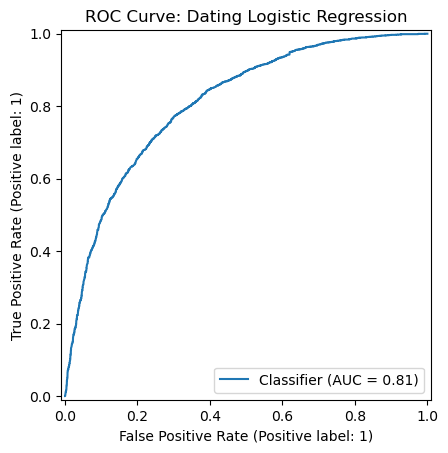

In [14]:
#========= ROC curve

from sklearn.metrics import RocCurveDisplay, roc_auc_score
import matplotlib.pyplot as plt

#----- compute AUC
auc = roc_auc_score(y_int, probs)

print(f"AUC: {auc:.3f}")

#-----draw the graph
RocCurveDisplay.from_predictions(y_int, probs)

#-----add title
plt.title("ROC Curve: Dating Logistic Regression")
plt.show()

## Task 2: 

### We are curious about:

Whether an **overconfidence proxy** is associated with **receiving a like**.

For each selected trait (e.g., sincerity), we define the overconfidence proxy as:

`<trait>_gap = self-rating of the trait − partner’s rating of the trait`

A positive gap indicates that the participant rated themselves more highly than their partner did. We will examine whether these trait-gap variables, together with other relevant factors such as gender and the partner’s ratings, are associated with whether the participant **receives a like from their partner**.

**Be careful:** This outcome is not whether the participant sends a like.

### Question 2.1: 

Please follow the hint in the code cell below to create the  `< trait >_gap` variable for each trait and create a new dataset `dating_sample_gap`for analysis.  Report the first 10-15 rows of this dataset in the cell output

*HINT:* Please read the variable decription (word doc in assignment folder) carefully to make sure you select the correct variables.  
 
<h4 style="color:blue">(Complete the code cells)</h4>

In [ ]:
#----create copy of the processed dataset
dating_sample_gap=dating_sample_0.copy()


#----group the variables
self_var=[...]
other_val=[...]


# create <base>_gap columns: <base>_gap = self - other (of course, this is just one way to do so)
bases = ["attr", "intel", "sinc", "fun"]

for b, s, o in zip(bases, self_var, other_val):
    dating_sample_gap[b + "_gap"] = dating_sample_gap[s] - dating_sample_gap[o]

#output
dating_sample_gap[0:10]

### Question 2.2: 

Please draw the bar chart to compare the mean of '_gap' between genders. Report the graph in the cell output. 
 
<h4 style="color:blue">(Complete the code cells)</h4>

In [ ]:
#------get mean of gap, group by gender
gap=dating_sample_gap.groupby(...)[].mean().T


#rename the columns of 'gap' table
gap.columns=['Female','Male']

#---- plot 
gap.plot(kind="bar", figsize=(10,7))
plt.title("Gender Comparison: Mean Trait Gaps by Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Question 2.3

We will examine which factors are associated with whether a participant **receives a like from their partner**. What is the dependent variable in this regression? Write the variable name and briefly explain why it represents receiving, rather than sending, a like.

<h4 style="color:blue">(Write your answer here)</h4>

### Question 2.4: 

In addition to the partner ratings and the trait-gap variables, what other explanatory variables would you include? Specify your regression model and justify your choices.
 

<h4 style="color:blue">(Write your answer here)</h4>

### Question 2.5: Please complete the regression

Estimate the logistic regression model that you proposed in Question 2.4 and display the complete regression output.

Using a significance level of 5%:

1. Report the coefficient estimate and p-value for each trait-gap variable.
2. Identify the statistically significant terms in the model.
3. For each significant term, indicate whether its estimated association with receiving a like is positive or negative.

<h4 style="color:blue">(Complete the code cells below)</h4>

In [ ]:
#======== predict dec_o (receiving likes)

#--- create the name list for predictors
num_cols = [...]

dating_sample_gap[num_cols] = dating_sample_gap[num_cols].apply(pd.to_numeric, errors="coerce")


#--- regression
design_overc = MS(...)

X_overc = design_overc.fit_transform(...)
y_overc = dating_sample_gap[...]

glm_overc = sm.GLM(...).fit()

#--- Results summary
glm_overc_summary=...
glm_overc_summary_sig=...

#---output
print(...)

### Question 2.6 — Interpretation and Critical Evaluation

**a) Interpret the statistically significant coefficients.**

For each significant coefficient, discuss:

- **Sign:** Is the estimated association positive or negative?
- **Magnitude:** Magnitudes of coefficients?
- **Plain-English:** What does the result mean in the context?


**b) Conduct a hypothesis test for one statistically significant variable.**

State the hypotheses and interpret the p-value.

- Variable: `_____`
- **Null hypothesis (H₀):**
- **Alternative hypothesis (H₁):**
- p-value: `_____`
- Conclusion at the 5% significance level:
- Interpretation in context:

**c) Does the overconfidence proxy matter?**

Use the results for all trait-gap variables to evaluate whether the overconfidence proxy is associated with receiving a like. Is the evidence consistent across traits, or is it limited to particular traits? Explain your conclusion.

**d) Evaluate the use of this model.**

Could this model be used to predict whether a participant will receive a like **before the date occurs**? Identify the relevant variables and explain your answer.

<h4 style="color:blue">(Write your answers here)</h4>

a)

b)

c)

d)

### Question 2.7 — Independent Model Extension and Reflection

Please propose **one meaningful extension** to the regression model used in Question 2.5. There is no single correct extension.


Do not select an extension simply because it produces a statistically significant result.

**a) Motivation**

Describe your proposed extension. What question does it help you investigate, and why is it relevant? Before estimating the model, explain what result you expect and why.

**b) Implementation**

Estimate the extended model. Clearly report:

- the regression;
- the modification you made;
- the relevant coefficient estimates and p-values; and
- any additional output needed to evaluate your extension.


In [ ]:
# write your code here

**c) Comparison**

Compare the extended model with your original model from Question 2.5. Identify at least two results that changed—or remained stable—and explain why you think this occurred.

**d) Conclusion**

What did your group learn from this extension? Explain whether it changes your conclusion about the relationship between the overconfidence proxy and receiving a like.

**e) Limitation**

Identify one limitation that is specific to your chosen extension. Explain what additional data or analysis would help address it.

Your grade will be based on the logic connecting your research question, modeling choice, results, and interpretation—not on whether your extension produces statistically significant findings.

<h4 style="color:blue">(Rrite your answers below)</h4>



c)

d)

e)